<a href="https://colab.research.google.com/github/sourish-bhattacharyya/fds-lab/blob/main/Sourish_Bhattacharyya_exp6_FDS_16014225009.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving kolkata_unified_dataset.csv to kolkata_unified_dataset.csv


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('kolkata_unified_dataset.csv')

cols = [
    'Volumetric_Moisture_Pct',
    'Soil_Temperature_C',
    'Sensor_Voltage_V'
]

data = df[cols].dropna().copy()

print("Dataset Overview:")
print(data.head())

Dataset Overview:
   Volumetric_Moisture_Pct  Soil_Temperature_C  Sensor_Voltage_V
0                    14.15               19.21             2.271
1                    14.14               19.36             2.232
2                    14.14               19.55             2.258
3                    14.14               19.52             2.248
4                    14.14               19.73             2.177


In [23]:
target_col = 'Volumetric_Moisture_Pct'

print("\nOriginal Attribute Statistics:")

print("Min:", data[target_col].min())
print("Max:", data[target_col].max())
print("Mean:", data[target_col].mean())
print("Std:", data[target_col].std())


Original Attribute Statistics:
Min: 8.91
Max: 19.63
Mean: 11.906643205705706
Std: 2.0256004248325774


In [24]:
for c in cols:
    min_val = data[c].min()
    max_val = data[c].max()

    if max_val != min_val:
        data[c + '_MinMax'] = (
            (data[c] - min_val) / (max_val - min_val)
        )
    else:
        data[c + '_MinMax'] = 0.0

In [25]:
for c in cols:
    mean_val = data[c].mean()
    std_val = data[c].std()

    if std_val != 0:
        data[c + '_ZScore'] = (
            (data[c] - mean_val) / std_val
        )
    else:
        data[c + '_ZScore'] = 0.0

In [26]:
for c in cols:
    max_abs_val = np.max(np.abs(data[c]))
    j = 0

    while max_abs_val / (10 ** j) >= 1:
        j += 1

    data[c + '_Decimal'] = data[c] / (10 ** j)

In [27]:
print("\nConsolidated Normalization Output:")

output_cols = cols.copy()

for c in cols:
    output_cols.extend([
        c + '_MinMax',
        c + '_ZScore',
        c + '_Decimal'
    ])

print(data[output_cols].head(10).round(3))


Consolidated Normalization Output:
   Volumetric_Moisture_Pct  Soil_Temperature_C  Sensor_Voltage_V  \
0                    14.15               19.21             2.271   
1                    14.14               19.36             2.232   
2                    14.14               19.55             2.258   
3                    14.14               19.52             2.248   
4                    14.14               19.73             2.177   
5                    14.14               19.91             2.203   
6                    14.15               19.59             2.235   
7                    14.12               19.75             2.223   
8                    14.15               19.75             2.229   
9                    14.16               19.72             2.245   

   Volumetric_Moisture_Pct_MinMax  Volumetric_Moisture_Pct_ZScore  \
0                           0.489                           1.108   
1                           0.488                           1.103   
2       

In [28]:
def kmeans_discretization(data, k=3, max_iter=100):
    np.random.seed(42)

    values = np.array(data)
    centroids = np.random.choice(values, size=k, replace=False)

    for i in range(max_iter):
        distances = np.abs(values[:, np.newaxis] - centroids)
        labels = np.argmin(distances, axis=1)

        new_centroids = np.array([
            values[labels == j].mean()
            if np.sum(labels == j) > 0
            else centroids[j]
            for j in range(k)
        ])

        if np.allclose(centroids, new_centroids):
            centroids = new_centroids
            break

        centroids = new_centroids

    distances = np.abs(values[:, np.newaxis] - centroids)
    labels = np.argmin(distances, axis=1)

    return labels, centroids


cluster_labels, final_centroids = kmeans_discretization(
    data[target_col].values, k=3
)

print("Final Centroids:", np.sort(final_centroids))

Final Centroids: [10.54448477 12.68124685 16.42298118]


In [29]:
sorted_indices = np.argsort(final_centroids)

label_map = {
    old_idx: f"Cluster_{rank + 1}"
    for rank, old_idx in enumerate(sorted_indices)
}

data['Cluster'] = cluster_labels
data['Moisture_Category'] = data['Cluster'].map(label_map)

print("\nDiscretized Data Output:")
print(data[[target_col, 'Moisture_Category']].head(10))


Discretized Data Output:
   Volumetric_Moisture_Pct Moisture_Category
0                    14.15         Cluster_2
1                    14.14         Cluster_2
2                    14.14         Cluster_2
3                    14.14         Cluster_2
4                    14.14         Cluster_2
5                    14.14         Cluster_2
6                    14.15         Cluster_2
7                    14.12         Cluster_2
8                    14.15         Cluster_2
9                    14.16         Cluster_2


In [30]:
print("\nDiscretization Cluster Summary:")

print(
    data.groupby('Moisture_Category')[target_col]
    .agg(['count', 'min', 'max', 'mean'])
)


Discretization Cluster Summary:
                   count    min    max       mean
Moisture_Category                                
Cluster_1          11820   8.91  11.61  10.544485
Cluster_2           7154  11.62  14.55  12.681247
Cluster_3           2338  14.56  19.63  16.422981


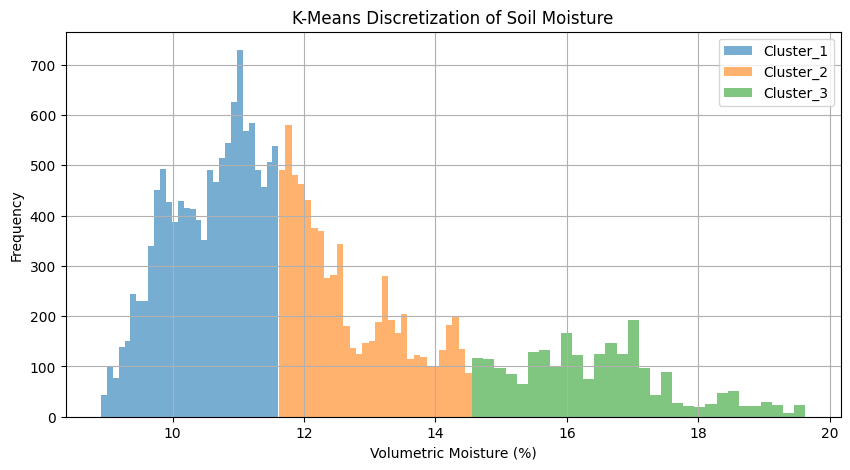

In [31]:
plt.figure(figsize=(10, 5))

for cluster in sorted(data['Moisture_Category'].unique()):
    subset = data[data['Moisture_Category'] == cluster]

    plt.hist(
        subset[target_col],
        bins=30,
        alpha=0.6,
        label=cluster
    )

plt.xlabel('Volumetric Moisture (%)')
plt.ylabel('Frequency')
plt.title('K-Means Discretization of Soil Moisture')
plt.legend()
plt.grid(True)
plt.show()